# IND320 Project work 3

**Author:** Inge Gilje Gunnarshaug

## 1. Introduction

This is the notebook for the third assignment in IND320. The corresponding streamlit app and github repository can be found here:

### Project links

- **GitHub repository:** https://github.com/IngeGiljeGunnarshaug/ind320-inge-gilje-gunnarshaug
- **Streamlit app:** https://ind320-inge-gilje-gunnarshaug.streamlit.app/

## 2. Environment and Imports

In [18]:
from pathlib import Path
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import numpy as np
import pandas as pd

## 3. NVE Atlas

### 3.1 Load data

In [ ]:
NVE = "https://kart.nve.no/enterprise/rest/services"

LAYERS = {
    "electricity": (
        f"{NVE}/Nettomraader/MapServer/0/query",
        "budomr"
    ),
    "precipitation": (
        f"{NVE}/Mapservices/Administrasjon2/MapServer/0/query",
        "REGION"
    )
}

DATA_DIR = Path("../data")



In [6]:
def load_nve_layer(name: str) -> gpd.GeoDataFrame:
    """Load an NVE geographical layer from cache or download it."""

    if name not in LAYERS:
        raise ValueError(f"Unknown layer: {name}")

    # Create the data directory if necessary
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    file_path = DATA_DIR / f"{name}.geojson"

    # Reuse the downloaded dataset if it already exists
    if file_path.exists():
        print(f"Loading {name} from local file.")
        return gpd.read_file(file_path)

    # Get the API endpoint and region identifier
    url, region_field = LAYERS[name]

    params = {
        "where": "1=1",
        "outFields": region_field,
        "returnGeometry": "true",
        "outSR": 4326,
        "maxAllowableOffset": 0.001,
        "f": "geojson"
    }

    # Download the geographical features
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    data = response.json()

    # Check that the API returned valid GeoJSON
    if data.get("type") != "FeatureCollection":
        raise ValueError(f"Unexpected API response: {data}")

    if not data.get("features"):
        raise ValueError(f"No geographical features returned for {name}")

    # Convert the response to a GeoDataFrame
    gdf = gpd.GeoDataFrame.from_features(
        data["features"],
        crs="EPSG:4326"
    )

    # Save locally for future notebook runs
    gdf.to_file(file_path, driver="GeoJSON")

    print(f"Downloaded {name}: {len(gdf)} features.")
    print(f"Saved to {file_path}")

    return gdf

In [7]:

electricity = load_nve_layer("electricity")
precipitation = load_nve_layer("precipitation")

# Inspect the number of features and region identifiers
print("Electricity areas:")
print(electricity["budomr"].value_counts())

print("\nPrecipitation areas:")
print(precipitation["REGION"].value_counts())


Downloaded electricity: 5 features.
Saved to ../data/electricity.geojson
Downloaded precipitation: 5 features.
Saved to ../data/precipitation.geojson
Electricity areas:
budomr
NO 1    1
NO 2    1
NO 3    1
NO 4    1
NO 5    1
Name: count, dtype: int64

Precipitation areas:
REGION
RV    1
RM    1
RN    1
RØ    1
RS    1
Name: count, dtype: int64


### 3.2 Visualize geographical boundaries

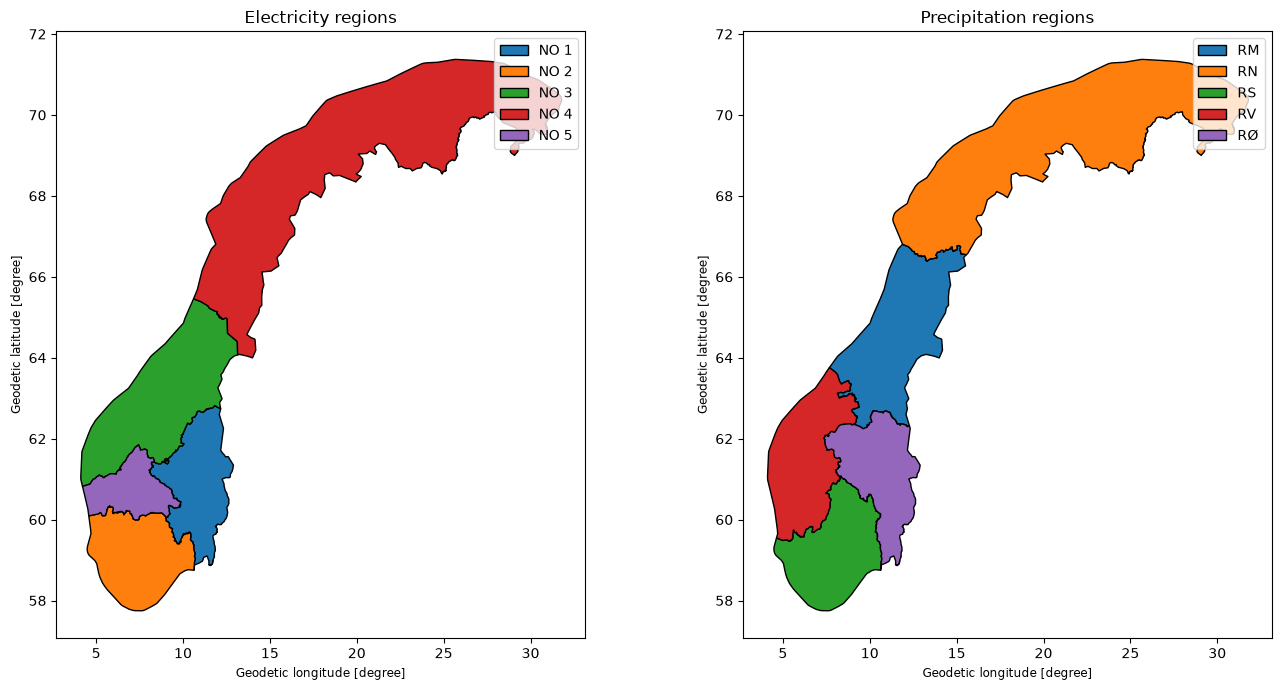

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Electricity regions
electricity.plot(
    ax=axes[0],
    column="budomr",
    legend=True,
    edgecolor="black"
)
axes[0].set_title("Electricity regions")

# Combined precipitation regions
precipitation.plot(
    ax=axes[1],
    column="REGION",
    legend=True,
    edgecolor="black"
)
axes[1].set_title("Precipitation regions")

plt.tight_layout()
plt.show()

### 3.3 Random sampling

In [15]:
def sample_locations(gdf, region_col, n=1000, seed=42):
    """Sample n random locations inside each geographical region."""

    rng = np.random.default_rng(seed)

    # Project to a coordinate system measured in metres
    projected = gdf.to_crs("EPSG:3035")

    samples = []

    for _, row in projected.iterrows():
        polygon = row.geometry
        region = row[region_col]

        minx, miny, maxx, maxy = polygon.bounds
        points = []

        # Rejection sampling: keep only points inside the polygon
        while len(points) < n:
            x = rng.uniform(minx, maxx)
            y = rng.uniform(miny, maxy)

            point = Point(x, y)

            if polygon.contains(point):
                points.append(point)

        for point in points:
            samples.append({
                "REGION": region,
                "geometry": point
            })

    # Convert sampled points back to latitude/longitude
    result = gpd.GeoDataFrame(
        samples,
        geometry="geometry",
        crs="EPSG:3035"
    )

    return result.to_crs("EPSG:4326")

In [16]:

electricity_points = sample_locations(
    electricity, region_col="budomr"
)

precipitation_points = sample_locations(
    precipitation, region_col="REGION"
)

print("Electricity locations:", len(electricity_points))
print("Precipitation locations:", len(precipitation_points))


Electricity locations: 5000
Precipitation locations: 5000


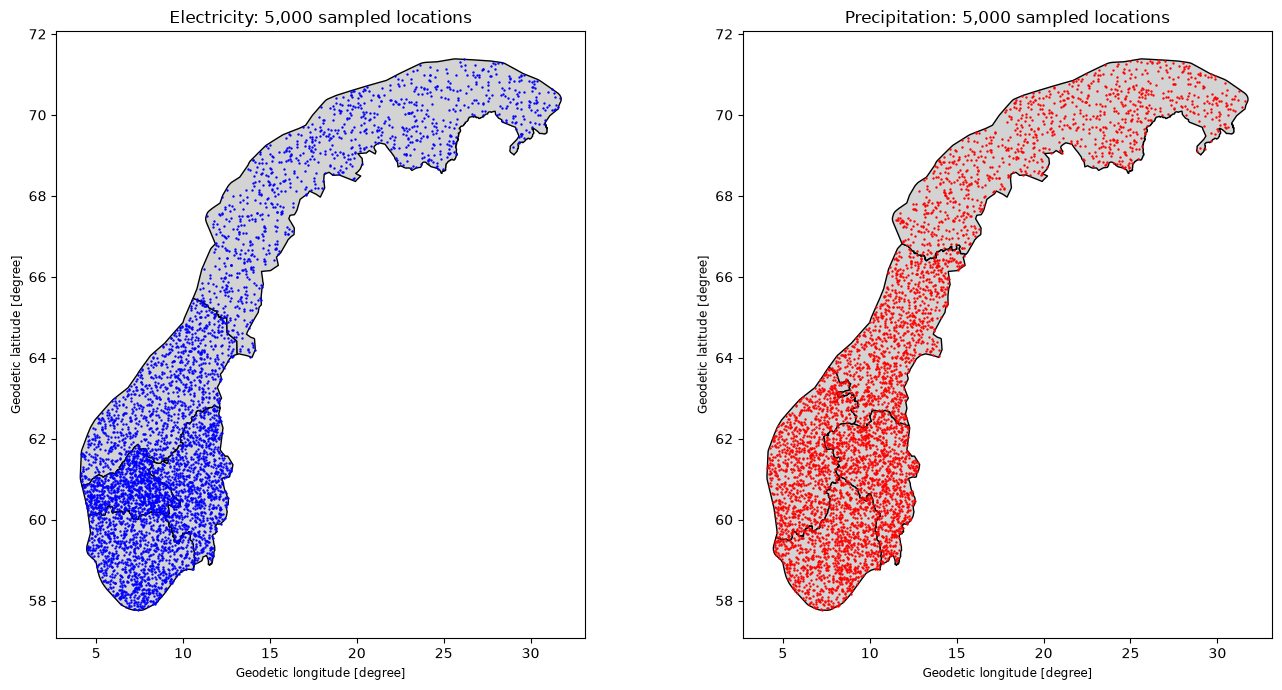

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

electricity.plot(ax=axes[0], color="lightgrey", edgecolor="black")
electricity_points.plot(
    ax=axes[0], markersize=0.5, color="blue"
)
axes[0].set_title("Electricity: 5,000 sampled locations")

precipitation.plot(ax=axes[1], color="lightgrey", edgecolor="black")
precipitation_points.plot(
    ax=axes[1], markersize=0.5, color="red"
)
axes[1].set_title("Precipitation: 5,000 sampled locations")

plt.tight_layout()
plt.show()

### 3.4 Save sampled locations

In [20]:
# Convert GeoDataFrames to regular DataFrames with coordinates
def points_to_dataframe(gdf, area_type):
    return pd.DataFrame({
        "area_type": area_type,
        "region": gdf["REGION"],
        "latitude": gdf.geometry.y,
        "longitude": gdf.geometry.x
    })

# Combine electricity and precipitation locations
locations = pd.concat([
    points_to_dataframe(electricity_points, "electricity"),
    points_to_dataframe(precipitation_points, "precipitation")
], ignore_index=True)

# Save all locations to one CSV file
file_path = DATA_DIR / "sampled_locations.csv"
locations.to_csv(file_path, index=False)

print(f"Saved {len(locations)} locations to {file_path}")
display(locations.head())

Saved 10000 locations to ../data/sampled_locations.csv


,area_type,region,latitude,longitude
0,electricity,NO 1,60.540200,11.725407
1,electricity,NO 1,61.588228,12.197488
2,electricity,NO 1,61.956291,11.739333
3,electricity,NO 1,62.111669,11.162875
4,electricity,NO 1,59.687971,10.151264
